# Global Shark Attack Data Analysis
Exploratory analysis of recorded shark attack incidents using Python, pandas and Matplotlib. The notebook examines fatality patterns by activity, reported provoked incidents by sex, and differences across identified shark species. Findings are descriptive and subject to reporting and data-quality limitations.

Dataset provenance: the cleaned dataset was supplied for university coursework; redistribution rights have not been established.

In [1]:
# Load the supplied cleaned dataset
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("data/shark-attacks-cleaned.csv", index_col=0)

print("\nThe First three rows:")
print(data.head(3))
print("\nDataset Information:")
data.info()



The First three rows:
   Year Month Country        Area        Type  Activity Sex   Age Fatal  \
0  2018   Jun     USA  California     Boating  Paddling   F  57.0     N   
1  2018   Jun     USA     Georgia  Unprovoked  Standing   F  11.0     N   
2  2018   Jun     USA      Hawaii     Invalid   Surfing   M  48.0     N   

  Injury Species  Size (min)  Size (max)  
0  Minor   White         NaN         NaN  
1  Minor     NaN         NaN         NaN  
2  Minor     NaN         NaN         NaN  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 6300 entries, 0 to 6301
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Year        6300 non-null   int64  
 1   Month       5781 non-null   object 
 2   Country     6250 non-null   object 
 3   Area        5845 non-null   object 
 4   Type        6296 non-null   object 
 5   Activity    5756 non-null   object 
 6   Sex         5731 non-null   object 
 7   Age   

In [2]:

print("\nThe Last few rows:")
print(data.tail())
print("\nSummary Statistics:")
print(data.describe())


The Last few rows:
      Year Month             Country               Area        Type  \
6297     0   NaN           AUSTRALIA  Western Australia  Unprovoked   
6298     0   NaN           AUSTRALIA  Western Australia  Unprovoked   
6299     0   NaN                 USA     North Carolina  Unprovoked   
6300     0   NaN              PANAMA                NaN  Unprovoked   
6301     0   NaN  CEYLON (SRI LANKA)   Eastern Province  Unprovoked   

          Activity Sex   Age Fatal Injury Species  Size (min)  Size (max)  
6297        Diving   M   NaN     Y  Fatal     NaN         NaN         NaN  
6298  Pearl diving   M   NaN     Y  Fatal     NaN         NaN         NaN  
6299      Swimming   M   NaN     Y  Fatal     NaN         NaN         NaN  
6300           NaN   M   NaN     Y  Fatal     NaN         NaN         NaN  
6301      Swimming   M  15.0     Y  Fatal     NaN         NaN         NaN  

Summary Statistics:


              Year          Age   Size (min)   Size (max)
count  6300.000000  3368.000000  1976.000000  1976.000000
mean   1927.272381    27.366093   255.439777   267.893219
std     281.116308    13.909223   136.289556   141.190139
min       0.000000     1.000000     2.000000     2.000000
25%    1942.000000    17.000000   150.000000   152.000000
50%    1977.000000    24.000000   213.000000   240.000000
75%    2005.000000    35.000000   350.000000   366.000000
max    2018.000000    87.000000  1006.000000  1006.000000


## Dataset overview and quality checks

The supplied cleaned dataset contains approximately 6,300 incident records with 13 columns. Fields include year, month, location, incident type, activity, reported sex, age, fatal outcome, injury, species and estimated shark size.

**Important limitations:** Some records have missing ages, species identifications or size estimates. A year of 0 should be treated as an unknown-date placeholder rather than a historical year. Recorded incidents are not a measure of population exposure or the probability of an attack while participating in an activity. The following comparisons are descriptive and depend on the available labels and known outcomes.

For reproducibility, the dataset is not included in this repository because redistribution permission has not been established. The analysis requires the appropriately licensed input file described in the README.

## Question 1 — How does recorded fatality proportion vary by activity?

The four most frequently recorded activities are selected by incident count. For each, the fatality proportion is calculated as fatal outcomes (`Fatal == 'Y'`) divided by incidents with a known fatal outcome (`Y` or `N`). This is **not** the probability of being attacked while doing the activity.

In [3]:
# count how many times each activity appears
activity_counts = {}
for i in range(len(data)):
    activity = data['Activity'].iloc[i]
    if str(activity) == 'nan':
        continue
    if activity in activity_counts:
        activity_counts[activity] = activity_counts[activity] + 1
    else:
        activity_counts[activity] = 1

# step 2: sort and get top 4 activities
sorted_activities = sorted(activity_counts, key=activity_counts.get, reverse=True)
common_activities = sorted_activities[:4]
print('Most common activities found:', common_activities)

# step 3: count total and fatal attacks for each activity
attacks_per_activity = {}
fatal_attacks_per_activity = {}

for i in range(len(data)):
    activity = data['Activity'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(activity) == 'nan':
        continue

    if activity in common_activities:
        if fatal == 'Y' or fatal == 'N':
            if activity in attacks_per_activity:
                attacks_per_activity[activity] = attacks_per_activity[activity] + 1
            else:
                attacks_per_activity[activity] = 1

            if fatal == 'Y':
                if activity in fatal_attacks_per_activity:
                    fatal_attacks_per_activity[activity] = fatal_attacks_per_activity[activity] + 1
                else:
                    fatal_attacks_per_activity[activity] = 1

# calculate fatality rate for each activity
print('Fatality rates by activity:')
for activity in attacks_per_activity:
    total = attacks_per_activity[activity]
    fatal = 0
    if activity in fatal_attacks_per_activity:
        fatal = fatal_attacks_per_activity[activity]
    rate = (fatal / total) * 100
    print(str(activity) + ': ' + str(round(rate, 1)) + '%')

Most common activities found: ['Surfing', 'Swimming', 'Fishing', 'Spearfishing']
Fatality rates by activity:
Surfing: 5.3%
Swimming: 39.2%
Fishing: 11.5%
Spearfishing: 13.4%


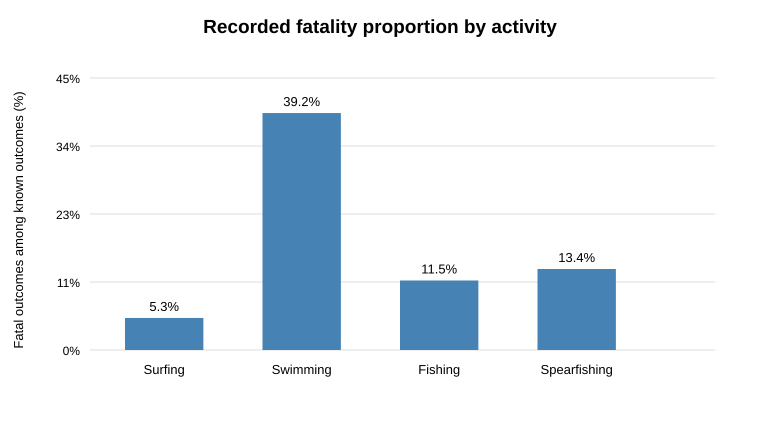

In [4]:
# Recalculate the plotted values from the counts above
activity_names = list(attacks_per_activity.keys())
fatality_rates = [
    round(100 * fatal_attacks_per_activity.get(activity, 0) / attacks_per_activity[activity], 1)
    for activity in activity_names
]

plt.figure(figsize=(10, 6))
bars = plt.bar(activity_names, fatality_rates, color='steelblue')
plt.ylabel('Fatal outcomes among recorded incidents (%)')
plt.title('Recorded fatality proportion by activity')
plt.ylim(0, max(fatality_rates) * 1.18)
plt.grid(axis='y', linestyle='--', alpha=0.4)
for bar, rate in zip(bars, fatality_rates):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{rate:.1f}%', ha='center')
plt.tight_layout()
plt.show()

### Result and interpretation

Among incidents with a known fatal outcome, the saved analysis reports **Surfing 5.3%**, **Swimming 39.2%**, **Fishing 11.5%** and **Spearfishing 13.4%**. Swimming has the highest recorded fatality proportion of these four activities; surfing has the lowest.

These percentages describe **severity among recorded incidents**, not attack likelihood or individual risk. Differences may reflect exposure, incident circumstances, reporting and missing outcomes; the data alone cannot establish why the proportions differ.

## Question 2 — How does the share of provoked incidents differ by reported sex?

This analysis compares the proportion of incidents labelled *Provoked* within records with reported sex M or F and incident type Provoked, Unprovoked or Boating. The classification describes the incident, not a person's intention or inherent risk-taking behaviour.

In [5]:
# define valid attack types and filter data manually
valid_attack_types = ['Unprovoked', 'Provoked', 'Boating']

filtered_rows = []
for i in range(len(data)):
    attack_type = data['Type'].iloc[i]
    gender = data['Sex'].iloc[i]

    if str(attack_type) == 'nan' or str(gender) == 'nan':
        continue

    if attack_type in valid_attack_types:
        if gender == 'M' or gender == 'F':
            filtered_rows.append(i)

gender_and_type_data = data.iloc[filtered_rows].copy()

# count total attacks for each gender
total_male_attacks = 0
total_female_attacks = 0

for i in range(len(gender_and_type_data)):
    gender = gender_and_type_data['Sex'].iloc[i]
    if gender == 'M':
        total_male_attacks = total_male_attacks + 1
    if gender == 'F':
        total_female_attacks = total_female_attacks + 1

# count provoked attacks for each gender
male_provoked_count = 0
female_provoked_count = 0

for i in range(len(gender_and_type_data)):
    gender = gender_and_type_data['Sex'].iloc[i]
    attack_type = gender_and_type_data['Type'].iloc[i]

    if gender == 'M' and attack_type == 'Provoked':
        male_provoked_count = male_provoked_count + 1
    if gender == 'F' and attack_type == 'Provoked':
        female_provoked_count = female_provoked_count + 1

# calculate percentages
male_provoked_percentage = (male_provoked_count / total_male_attacks) * 100
female_provoked_percentage = (female_provoked_count / total_female_attacks) * 100

print('Total male attacks: ' + str(total_male_attacks))
print('Male provoked attacks: ' + str(male_provoked_count) + ' (' + str(round(male_provoked_percentage, 1)) + '%)')
print()
print('Total female attacks: ' + str(total_female_attacks))
print('Female provoked attacks: ' + str(female_provoked_count) + ' (' + str(round(female_provoked_percentage, 1)) + '%)')
print()

# breakdown by attack type and gender
all_types = []
for i in range(len(gender_and_type_data)):
    attack_type = gender_and_type_data['Type'].iloc[i]
    if attack_type not in all_types:
        all_types.append(attack_type)

breakdown = {}
for attack_type in all_types:
    male_count = 0
    female_count = 0
    for i in range(len(gender_and_type_data)):
        if gender_and_type_data['Type'].iloc[i] == attack_type:
            if gender_and_type_data['Sex'].iloc[i] == 'M':
                male_count = male_count + 1
            if gender_and_type_data['Sex'].iloc[i] == 'F':
                female_count = female_count + 1
    breakdown[attack_type] = {'M': male_count, 'F': female_count}

print('Full breakdown by attack type:')
print('Type'.ljust(15) + 'M'.ljust(10) + 'F')
print('-' * 30)
for attack_type in breakdown:
    m = breakdown[attack_type]['M']
    f = breakdown[attack_type]['F']
    print(str(attack_type).ljust(15) + str(m).ljust(10) + str(f))

Total male attacks: 4514
Male provoked attacks: 494 (10.9%)

Total female attacks: 566
Female provoked attacks: 22 (3.9%)

Full breakdown by attack type:
Type           M         F
------------------------------
Boating        124       9
Unprovoked     3896      535
Provoked       494       22


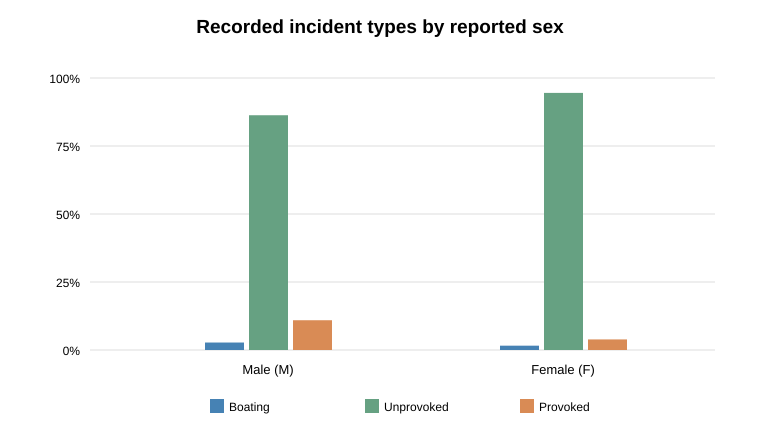

In [6]:
# Percentages within each reported-sex group, using the breakdown above
all_types = ['Boating', 'Unprovoked', 'Provoked']
male_percentages = {t: 100 * breakdown[t]['M'] / total_male_attacks for t in all_types}
female_percentages = {t: 100 * breakdown[t]['F'] / total_female_attacks for t in all_types}

import numpy as np
x = np.arange(2)
width = 0.24
fig, ax = plt.subplots(figsize=(10, 6))
for j, attack_type in enumerate(all_types):
    ax.bar(x + (j - 1) * width,
           [male_percentages[attack_type], female_percentages[attack_type]],
           width, label=attack_type)
ax.set_xticks(x)
ax.set_xticklabels(['Male (M)', 'Female (F)'])
ax.set_ylabel('Share of included incidents (%)')
ax.set_title('Recorded incident types by reported sex')
ax.legend(title='Incident type')
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Result and interpretation

The saved results show **494 of 4,514** included male-labelled incidents were provoked (**10.9%**) versus **22 of 566** female-labelled incidents (**3.9%**). Thus, provoked incidents constitute a higher *share of recorded incidents* in the male-labelled group.

This does **not** establish that men generally provoke sharks more often: exposure, activities, reporting practices and the substantial difference in group sizes may affect the comparison. Records with missing or other sex labels and excluded incident types are not represented.

## Question 3 — How do identified species compare in attack count and fatality proportion?

Attack frequency and fatality proportion are different measures. This comparison is limited to species with at least 20 records meeting the analysis filters. Unknown species are excluded, and species identification may be uncertain. A higher count in this dataset does not by itself establish greater real-world danger.

In [7]:
# count how many attacks each species has
species_counts = {}
for i in range(len(data)):
    species = data['Species'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(species) == 'nan' or str(fatal) == 'nan':
        continue

    if species in species_counts:
        species_counts[species] = species_counts[species] + 1
    else:
        species_counts[species] = 1

# keep only species with at least 20 attacks
common_species = []
for species in species_counts:
    if species_counts[species] >= 20:
        common_species.append(species)

# count total and fatal attacks for each common species
attacks_per_species = {}
fatal_per_species = {}

for i in range(len(data)):
    species = data['Species'].iloc[i]
    fatal = data['Fatal'].iloc[i]

    if str(species) == 'nan' or str(fatal) == 'nan':
        continue

    if species in common_species:
        if fatal == 'Y' or fatal == 'N':
            if species in attacks_per_species:
                attacks_per_species[species] = attacks_per_species[species] + 1
            else:
                attacks_per_species[species] = 1

            if fatal == 'Y':
                if species in fatal_per_species:
                    fatal_per_species[species] = fatal_per_species[species] + 1
                else:
                    fatal_per_species[species] = 1

# calculate fatality rate for each species
fatal_rates = {}
for species in attacks_per_species:
    total = attacks_per_species[species]
    fatal = 0
    if species in fatal_per_species:
        fatal = fatal_per_species[species]
    fatal_rates[species] = (fatal / total) * 100

# sort species by attack count and print summary
sorted_species = sorted(attacks_per_species, key=attacks_per_species.get, reverse=True)

print('Species comparison:')
print('Species'.ljust(25) + 'Attack Count'.ljust(20) + 'Fatality Rate')
print('-' * 55)
for species in sorted_species:
    total = attacks_per_species[species]
    rate = round(fatal_rates[species], 1)
    print(str(species).ljust(25) + str(total).ljust(20) + str(rate) + '%')

Species comparison:
Species                  Attack Count        Fatality Rate
White                    173                 27.7%
Tiger                     80                 35.0%
Bull                      56                 33.9%
Wobbegong                 21                  0.0%
Zambesi                   20                 40.0%


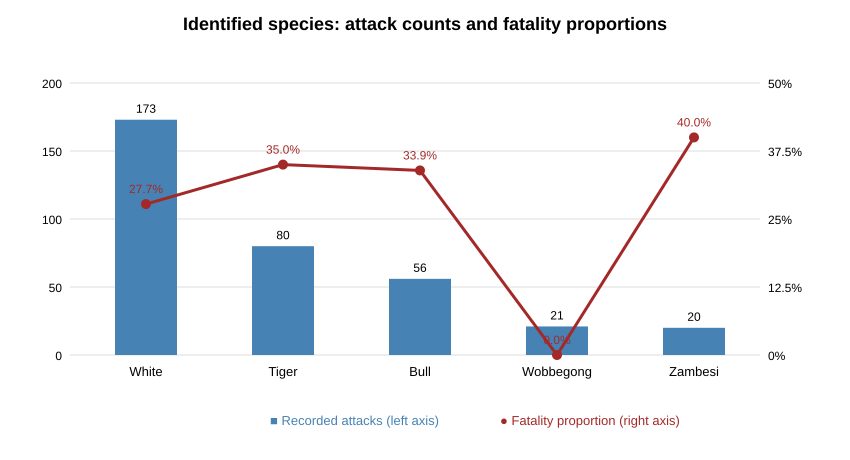

In [8]:
# Build the chart directly from the computed dictionaries
species_stats = pd.DataFrame([
    {'Species': species,
     'total_attacks': attacks_per_species[species],
     'fatality_rate': fatal_rates[species]}
    for species in sorted_species
])

fig, ax = plt.subplots(figsize=(11, 6))
x = range(len(species_stats))
ax.bar(x, species_stats['total_attacks'], color='steelblue', label='Recorded attacks')
ax.set_ylabel('Recorded attacks (count)')
ax.set_xticks(list(x))
ax.set_xticklabels(species_stats['Species'], rotation=30, ha='right')
ax.set_title('Identified species: attack counts and fatality proportions')
ax2 = ax.twinx()
ax2.plot(list(x), species_stats['fatality_rate'], color='darkred', marker='o',
         linewidth=2, label='Fatality proportion')
ax2.set_ylabel('Fatal outcomes among known outcomes (%)')
ax2.set_ylim(0, max(45, species_stats['fatality_rate'].max() * 1.2))
for i, rate in enumerate(species_stats['fatality_rate']):
    ax2.annotate(f'{rate:.1f}%', (i, rate), xytext=(0, 7),
                 textcoords='offset points', ha='center', color='darkred')
fig.tight_layout()
plt.show()

### Result and interpretation

The saved results report **White: 173 attacks, 27.7% fatal**; **Tiger: 80, 35.0%**; **Bull: 56, 33.9%**; **Wobbegong: 21, 0.0%**; and **Zambesi: 20, 40.0%**.

**White** has the largest recorded attack count among these identified species, while **Zambesi** has the highest observed fatality proportion in this selected group. The latter estimate is based on only 20 records and is therefore especially sensitive to small changes. The measures should not be collapsed into an unsupported single ranking of the 'most dangerous' species.

### Overall conclusion

Across the available recorded incidents, fatality proportions differ by activity, the share of incidents labelled provoked differs by reported sex, and identified species differ in both attack counts and fatality proportions. These are descriptive patterns, **not causal explanations or population-adjusted risk estimates**. Missing data, classification uncertainty and reporting bias limit generalisation.